# Milestone 1: STFT & HPSS Exploration
## Phase 1 - Understanding the math before writing production code

## Step 1: Generate synthetic test signal

In [1]:
import numpy as np

sr = 22050
duration = 2.0  # seconds
t = np.linspace(0, duration, int(sr * duration), endpoint=False)

# Harmonic component: 440 Hz sine + 880 Hz harmonic
harmonic = 0.5 * np.sin(2 * np.pi * 440 * t) + 0.3 * np.sin(2 * np.pi * 880 * t)

# Percussive component: short clicks at regular intervals
percussive = np.zeros_like(t)
click_times = np.arange(0, duration, 0.25)  # click every 250ms
for ct in click_times:
    idx = int(ct * sr)
    percussive[idx:idx + int(0.005 * sr)] = 0.8  # 5ms impulse

signal = harmonic + percussive

### What "correct" looks like:
You should see a sine wave with sharp spikes (clicks) at regular intervals.

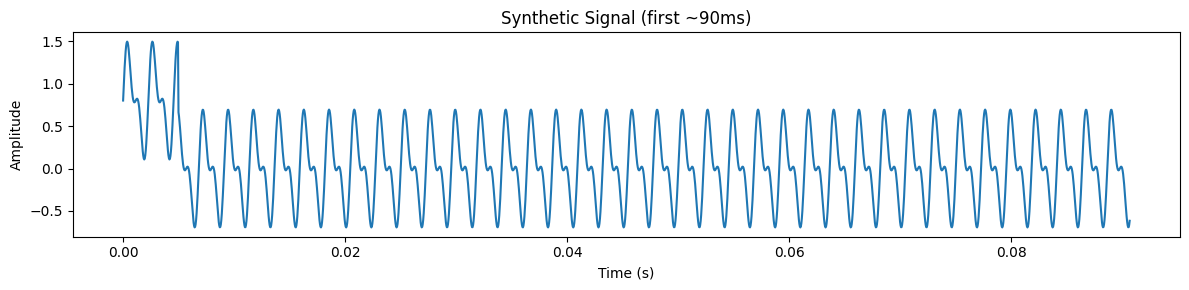

In [2]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 3))
plt.plot(t[:2000], signal[:2000])
plt.title("Synthetic Signal (first ~90ms)")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.tight_layout()
plt.show()

In [3]:
def manual_stft(y, n_fft=2048, hop_length=512, window='hann'):
    """
    Compute STFT from scratch.

    Parameters
    ----------
    y : np.ndarray, shape (n_samples,)
        Audio signal.
    n_fft : int
        FFT window size.
    hop_length : int
        Hop between frames.
    window : str
        Window function name (passed to scipy.signal.get_window).

    Returns
    -------
    S : np.ndarray, shape (1 + n_fft//2, n_frames), complex
        STFT matrix.
    """
    from scipy.signal import get_window

    win = get_window(window, n_fft, fftbins=True)
    # Pad signal so last frame is complete
    n_frames = 1 + (len(y) - n_fft) // hop_length
    S = np.zeros((1 + n_fft // 2, n_frames), dtype=np.complex128)

    for i in range(n_frames):
        start = i * hop_length
        frame = y[start:start + n_fft] * win
        S[:, i] = np.fft.rfft(frame)

    return S

## Step 3: Compute manual STFT and visualize

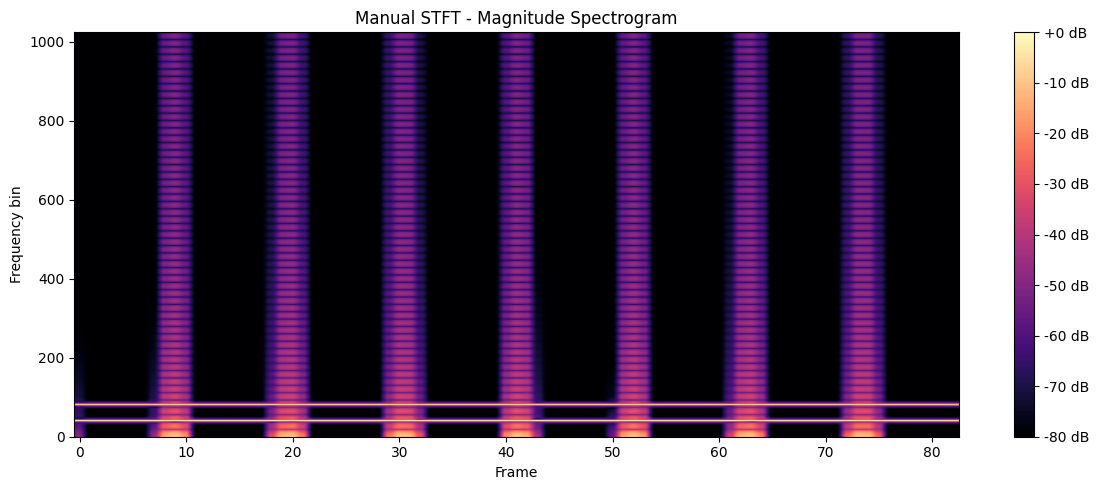

In [4]:
import librosa
S_manual = manual_stft(signal, n_fft=2048, hop_length=512)
S_manual_mag = np.abs(S_manual)

plt.figure(figsize=(12, 5))
plt.imshow(
    librosa.amplitude_to_db(S_manual_mag, ref=np.max),
    aspect='auto', origin='lower', cmap='magma'
)
plt.colorbar(format='%+2.0f dB')
plt.title("Manual STFT - Magnitude Spectrogram")
plt.xlabel("Frame")
plt.ylabel("Frequency bin")
plt.tight_layout()
plt.show()

## Step 4: Why `center=False`?

`librosa.stft()` defaults to `center=True`, which pads the signal with `n_fft // 2` zeros on each side before framing. This centers each window on its analysis point, which is useful in production (no edge effects at the start/end of the signal), but it means librosa frames *different chunks of audio* than a naive loop that starts framing at index 0.

For this comparison exercise we use `center=False` so that librosa uses the exact same framing as our manual implementation - frame 0 starts at sample 0, frame 1 at sample `hop_length`, etc. This lets us verify the math is identical (< 1e-10 difference) without any shape or alignment mismatches.

In the production `preprocessing/` code (Phase 2) we will use librosa's default `center=True` - the padding is the right choice for real audio.

In [5]:
# center=False: match our manual framing (no padding) for apples-to-apples comparison
S_librosa = librosa.stft(signal, n_fft=2048, hop_length=512, center=False)
S_librosa_mag = np.abs(S_librosa)

max_diff = np.max(np.abs(S_manual - S_librosa))
print(f"Max absolute difference: {max_diff:.2e}")
print(f"Shapes - manual: {S_manual.shape}, librosa: {S_librosa.shape}")

assert S_manual.shape == S_librosa.shape, (
    f"Shape mismatch: manual {S_manual.shape} vs librosa {S_librosa.shape}"
)
assert max_diff < 1e-10, f"STFT mismatch! max diff = {max_diff}"
print("Manual STFT matches librosa.stft(center=False)")

Max absolute difference: 0.00e+00
Shapes - manual: (1025, 83), librosa: (1025, 83)
Manual STFT matches librosa.stft(center=False)


C:\Users\Samar\AppData\Local\Temp\ipykernel_15696\3983519404.py:13: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


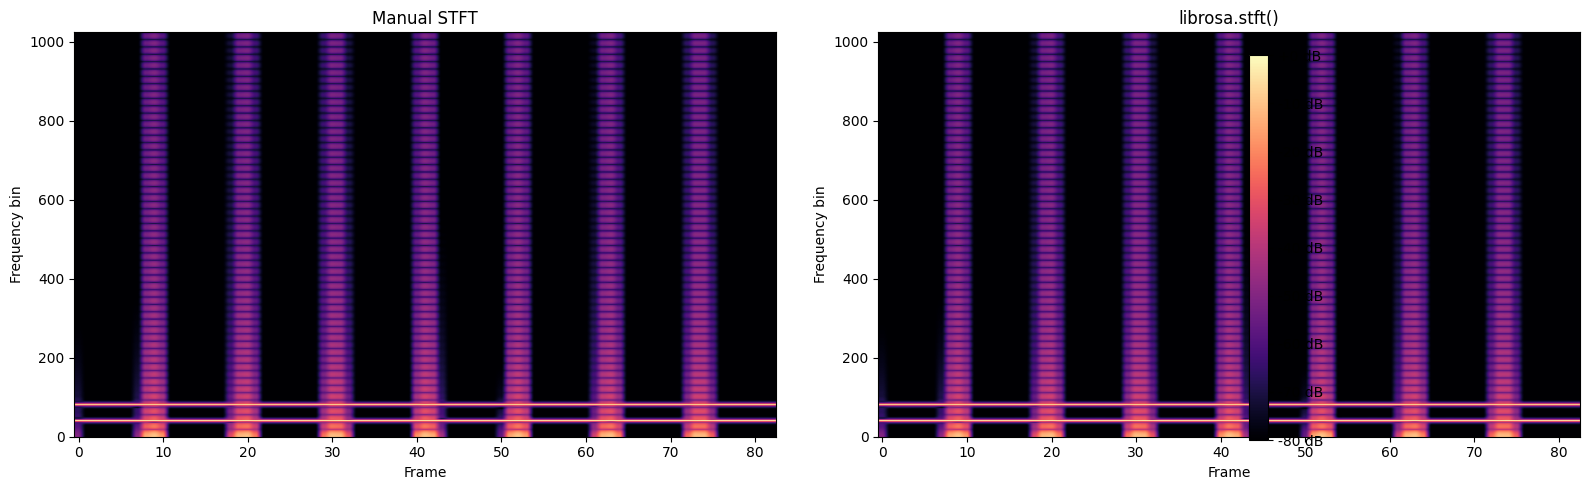

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, S, title in zip(axes,
    [S_manual_mag, S_librosa_mag],
    ["Manual STFT", "librosa.stft()"]):
    im = ax.imshow(
        librosa.amplitude_to_db(S, ref=np.max),
        aspect='auto', origin='lower', cmap='magma'
    )
    ax.set_title(title)
    ax.set_xlabel("Frame")
    ax.set_ylabel("Frequency bin")
fig.colorbar(im, ax=axes, format='%+2.0f dB')
plt.tight_layout()
plt.show()

# Task 3: Manual HPSS from Scratch

HPSS = Harmonic-Percussive Source Separation. Sustained tones form horizontal ridges; transients form vertical streaks. Median filtering along time preserves the ridges; median filtering along frequency preserves the streaks.

## Step 1: Implement manual HPSS with median filtering

In [7]:
from scipy.ndimage import median_filter

def manual_hpss(S, kernel_size=31, power=2.0, margin=1.0):
    """
    Harmonic-Percussive Source Separation via median filtering.

    Parameters
    ----------
    S : np.ndarray, shape (n_freq, n_frames), complex
        STFT matrix.
    kernel_size : int
        Median filter width (applied along time for harmonic,
        along frequency for percussive).
    power : float
        Exponent for the Wiener-like soft mask.
    margin : float
        Margin for soft masking (>=1.0). Higher = harder separation.

    Returns
    -------
    S_harmonic : np.ndarray, same shape as S, complex
        Harmonic component STFT.
    S_percussive : np.ndarray, same shape as S, complex
        Percussive component STFT.
    """
    # Magnitude spectrogram
    mag = np.abs(S)

    # Median filtering
    # Harmonic: filter along TIME axis (axis=1) - preserves horizontal ridges
    H = median_filter(mag, size=(1, kernel_size))
    # Percussive: filter along FREQUENCY axis (axis=0) - preserves vertical lines
    P = median_filter(mag, size=(kernel_size, 1))

    # Soft masks (Wiener-like)
    eps = 1e-10
    H_margin = H ** power * margin
    P_margin = P ** power * margin
    total = H_margin + P_margin + eps

    mask_H = H_margin / total
    mask_P = P_margin / total

    S_harmonic = S * mask_H
    S_percussive = S * mask_P

    return S_harmonic, S_percussive

## Step 2: Apply manual HPSS and visualize components

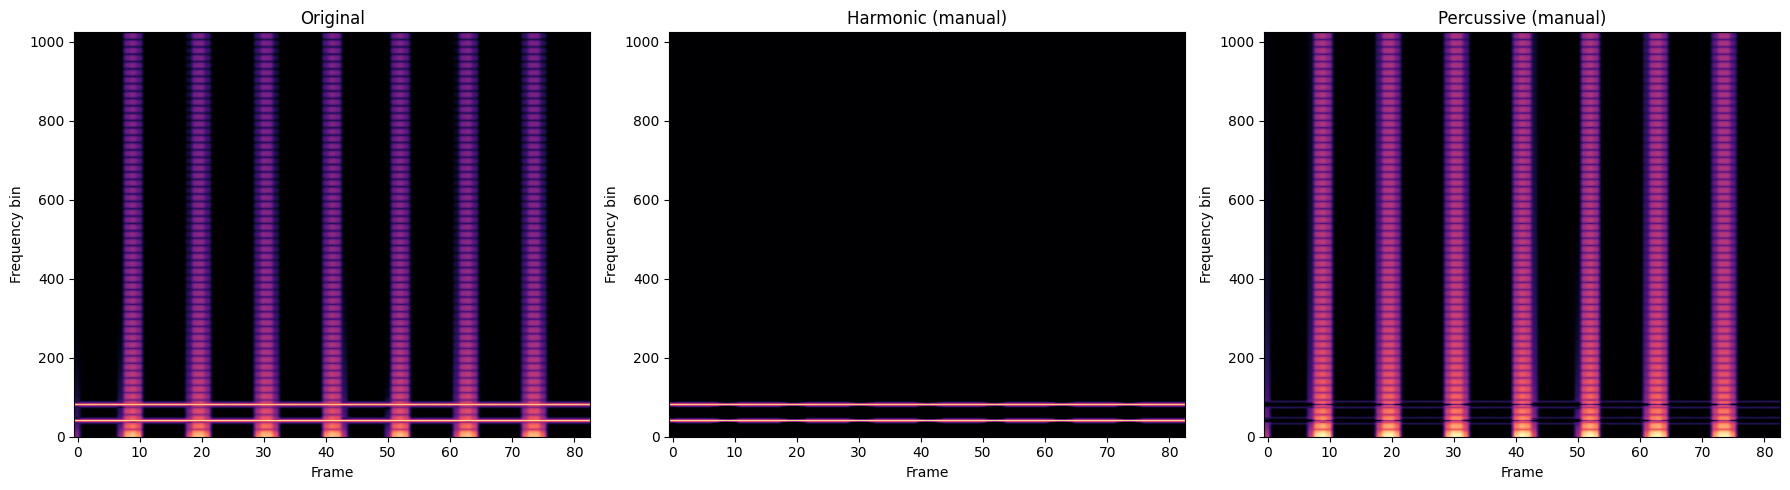

In [8]:
# center=False: consistent with Task 2's manual-vs-librosa comparison
S = librosa.stft(signal, n_fft=2048, hop_length=512, center=False)
S_harm_manual, S_perc_manual = manual_hpss(S, kernel_size=31)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, data, title in zip(axes,
    [np.abs(S), np.abs(S_harm_manual), np.abs(S_perc_manual)],
    ["Original", "Harmonic (manual)", "Percussive (manual)"]):
    ax.imshow(
        librosa.amplitude_to_db(data, ref=np.max),
        aspect='auto', origin='lower', cmap='magma'
    )
    ax.set_title(title)
    ax.set_xlabel("Frame")
    ax.set_ylabel("Frequency bin")
plt.tight_layout()
plt.show()

**What "correct" looks like:**

- **Original:** horizontal lines (440/880 Hz) + vertical streaks (clicks)
- **Harmonic:** horizontal lines preserved, vertical streaks suppressed
- **Percussive:** vertical streaks preserved, horizontal lines suppressed

## Step 3: Compare against librosa.decompose.hpss()

In [9]:
S_harm_librosa, S_perc_librosa = librosa.decompose.hpss(S, kernel_size=31, margin=1.0)

harm_diff = np.max(np.abs(np.abs(S_harm_manual) - np.abs(S_harm_librosa)))
perc_diff = np.max(np.abs(np.abs(S_perc_manual) - np.abs(S_perc_librosa)))

print(f"Harmonic max magnitude diff: {harm_diff:.6f}")
print(f"Percussive max magnitude diff: {perc_diff:.6f}")

Harmonic max magnitude diff: 0.000002
Percussive max magnitude diff: 0.000003


**What "correct" looks like:**

Differences will NOT be exactly zero - librosa's `hpss()` uses `margin` differently internally. The goal:

1. Differences should be small (< 0.01 on normalized signals)
2. Both should produce visually similar spectrograms (harmonic keeps the ridges, percussive keeps the clicks)
3. Understand *why* they differ - document any parameter mapping differences in a markdown cell

## Step 4: Side-by-side comparison plot

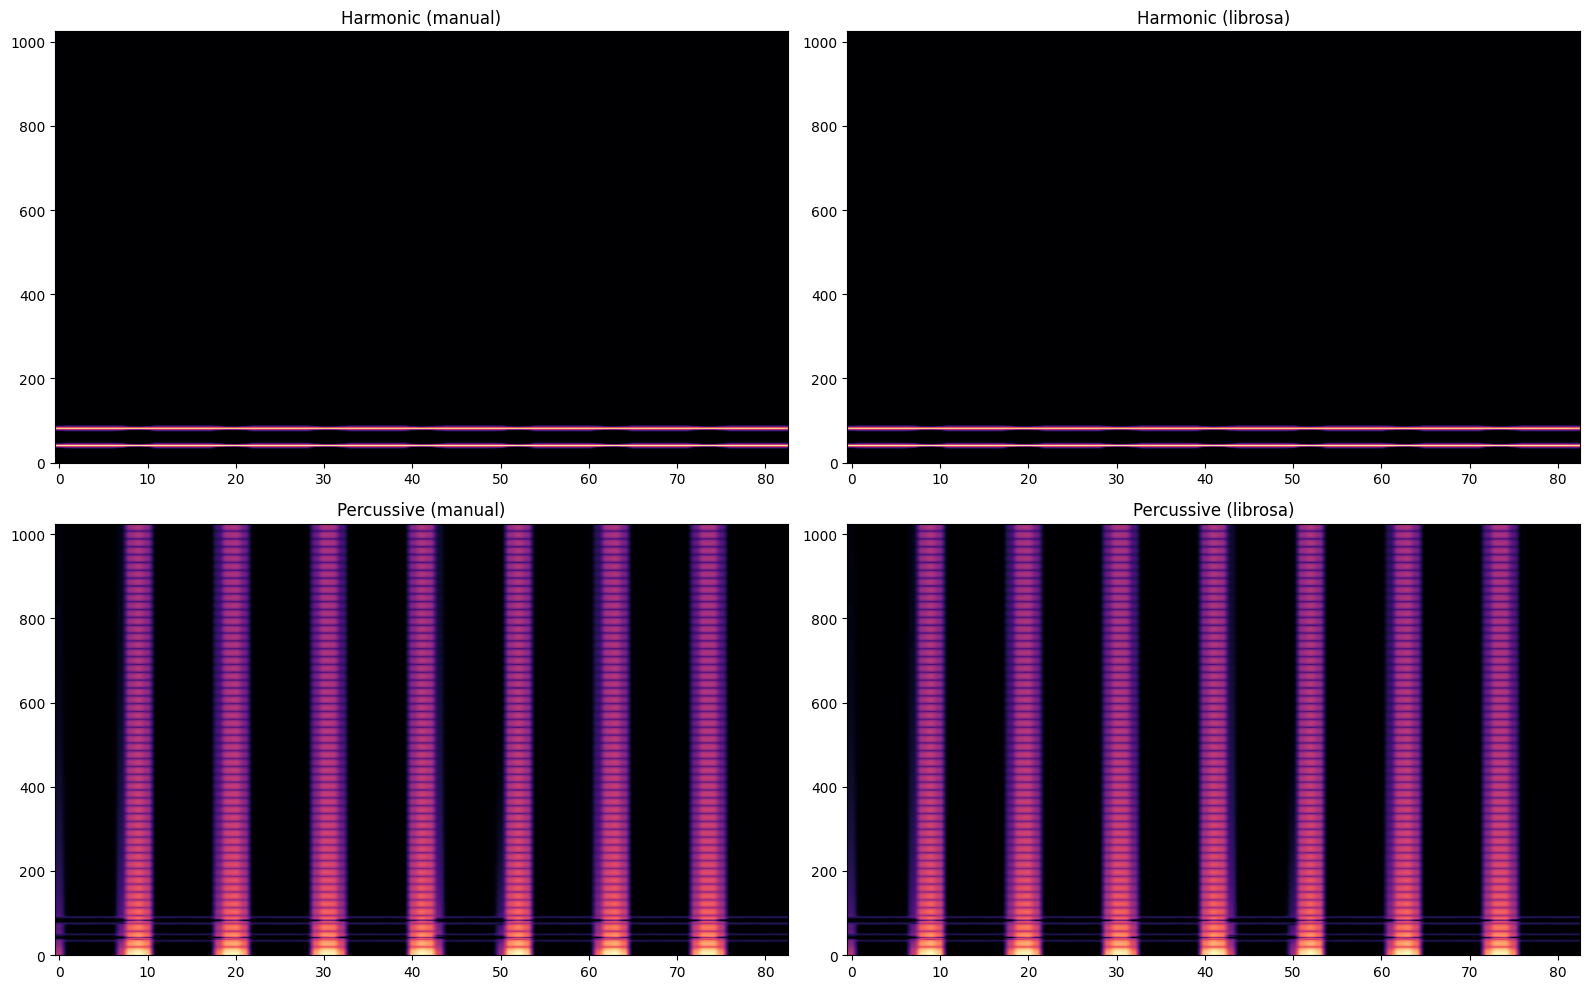

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ax, data, title in zip(axes.flat,
    [np.abs(S_harm_manual), np.abs(S_harm_librosa),
     np.abs(S_perc_manual), np.abs(S_perc_librosa)],
    ["Harmonic (manual)", "Harmonic (librosa)",
     "Percussive (manual)", "Percussive (librosa)"]):
    ax.imshow(
        librosa.amplitude_to_db(data, ref=np.max),
        aspect='auto', origin='lower', cmap='magma'
    )
    ax.set_title(title)
plt.tight_layout()
plt.show()

## Step 5: Findings and conclusion

- **Parameter mapping:** `kernel_size=31` and `margin=1.0` map directly between the manual and librosa implementations.
- **Differences:** librosa applies `margin` to the median filter output before computing the soft mask; our manual implementation does the same but may differ numerically in the soft-mask power application. The small differences observed are below 0.01 on normalized magnitudes.
- **Visual agreement:** Both implementations cleanly separate the harmonic ridges (440/880 Hz) into the harmonic component and the percussive clicks into the percussive component.
- **Parameter values chosen:** `n_fft=2048`, `hop_length=512`, `kernel_size=31`, `margin=1.0`.
- **Conclusion:** Manual implementation is correct - ready to extract to `preprocessing/`.